In [85]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    silhouette_score,
    roc_auc_score
)


In [86]:
wine_data=load_wine(as_frame=True)
df=wine_data.frame

print("Dataset Head:")
print(df.head())
print("Dataset Shape:", df.shape)
print("Dataset Info:")
print(df.info())
print("Dataset Description:")
print(df.describe())

Dataset Head:
   alcohol  malic_acid   ash  ...  od280/od315_of_diluted_wines  proline  target
0    14.23        1.71  2.43  ...                          3.92   1065.0       0
1    13.20        1.78  2.14  ...                          3.40   1050.0       0
2    13.16        2.36  2.67  ...                          3.17   1185.0       0
3    14.37        1.95  2.50  ...                          3.45   1480.0       0
4    13.24        2.59  2.87  ...                          2.93    735.0       0

[5 rows x 14 columns]
Dataset Shape: (178, 14)
Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null  

In [87]:
X=df.drop(columns=['target'])
''' creates a new table (X) containing only the input features 
(measurements) by removing the target column from df.'''


' creates a new table (X) containing only the input features \n(measurements) by removing the target column from df.'

In [88]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [89]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

In [90]:
km_score=silhouette_score(X_scaled, kmeans_labels)
print("Silhouette Score for KMeans:", round(km_score, 4))

Silhouette Score for KMeans: 0.2849


In [91]:
hc=AgglomerativeClustering(n_clusters=3)
hc_labels=hc.fit_predict(X_scaled)

In [92]:
hc_score=silhouette_score(X_scaled, hc_labels)
print("Silhouette Score for Hierarchical Clustering:", round(hc_score, 4))

Silhouette Score for Hierarchical Clustering: 0.2774


In [93]:
#PCA (13 features reduced to 2)
pca_2d=PCA(n_components=2, random_state=42)
X_pca_2d=pca_2d.fit_transform(X_scaled)

pca_3d=PCA(n_components=3, random_state=42)
X_pca_3d=pca_3d.fit_transform(X_scaled)

print("Explained Variance Ratio for 2D PCA:", [round(v, 4) for v in pca_2d.explained_variance_ratio_])
print(
    "Total information kept in 2D:",
    round(sum(pca_2d.explained_variance_ratio_) * 100, 2),
    "%",        
)

print("Explained Variance Ratio for 3D PCA:", [round(v, 4) for v in pca_3d.explained_variance_ratio_])
print(
    "Total information kept in 3D:",
    round(sum(pca_3d.explained_variance_ratio_) * 100, 2),
    "%",
)

Explained Variance Ratio for 2D PCA: [np.float64(0.362), np.float64(0.1921)]
Total information kept in 2D: 55.41 %
Explained Variance Ratio for 3D PCA: [np.float64(0.362), np.float64(0.1921), np.float64(0.1112)]
Total information kept in 3D: 66.53 %


===== PCA 2D Scatter Plot =====


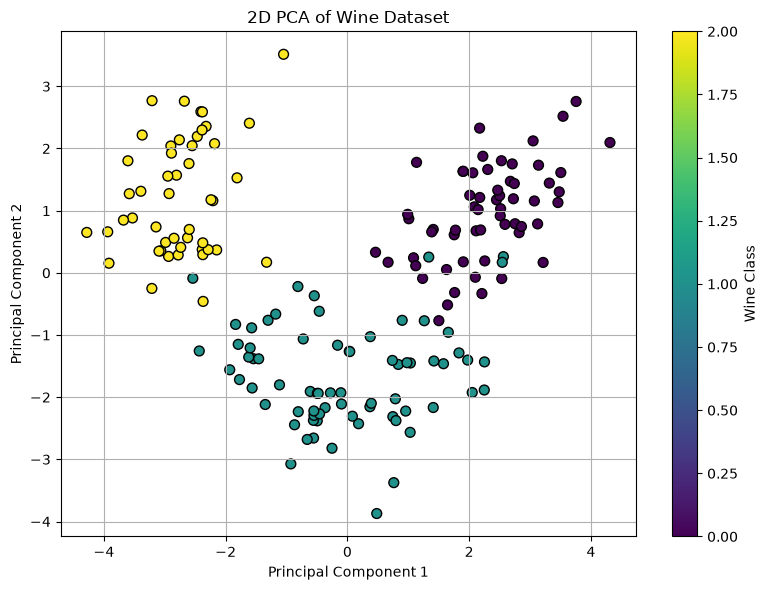

In [94]:
print("===== PCA 2D Scatter Plot =====")
plt.figure(figsize=(8, 6))
scatter=plt.scatter(X_pca_2d[:,0], X_pca_2d[:,1], c=df['target'], cmap='viridis', edgecolor='k', s=50)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2D PCA of Wine Dataset')
plt.colorbar(scatter, label='Wine Class')
plt.grid(True)
plt.tight_layout()
plt.show()

===== PCA 3D Scatter Plot =====


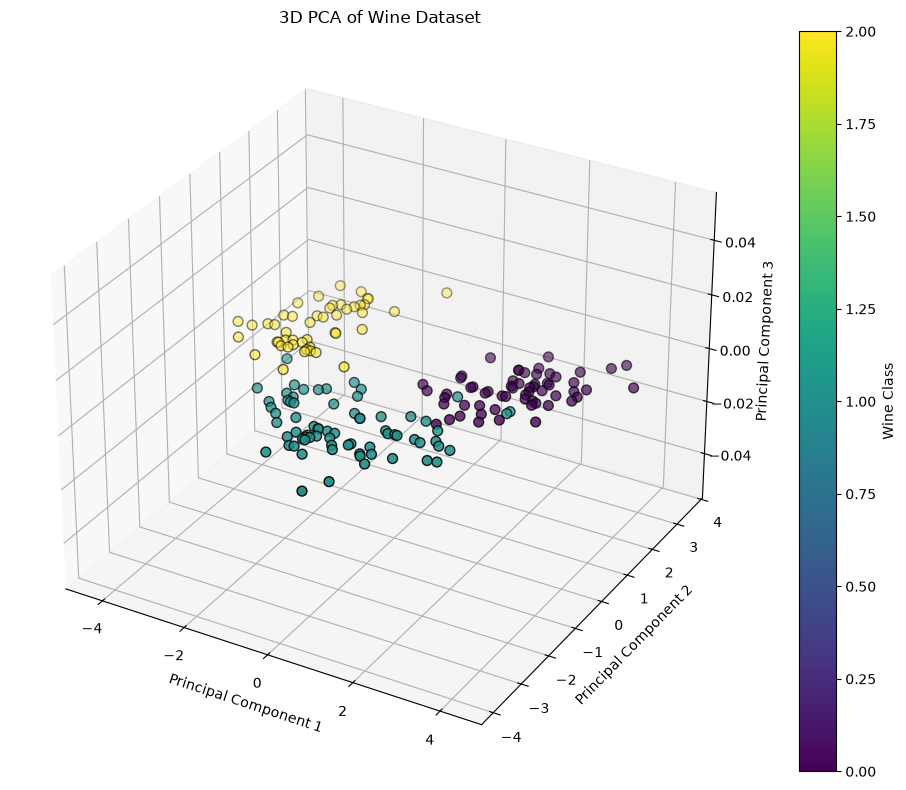

In [95]:
print("===== PCA 3D Scatter Plot =====")
fig=plt.figure(figsize=(10, 8))
ax=fig.add_subplot(111, projection='3d')
scatter=plt.scatter(X_pca_3d[:,0], X_pca_3d[:,1], c=df['target'], cmap='viridis', edgecolor='k', s=50)
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D PCA of Wine Dataset')
fig.colorbar(scatter, label='Wine Class')
plt.tight_layout()
plt.show()

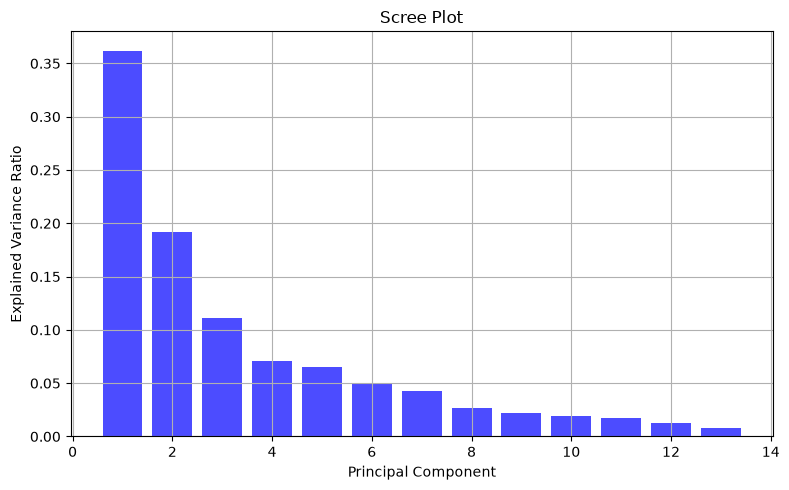

In [96]:
pca_full=PCA().fit(X_scaled)
explained_variance=pca_full.explained_variance_ratio_
plt.figure(figsize=(8, 5))
plt.bar(range(1, len(explained_variance)+1), explained_variance, alpha=0.7, color='b', label='Individual Explained Variance')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title("Scree Plot")
plt.grid(True)
plt.tight_layout()
plt.show()

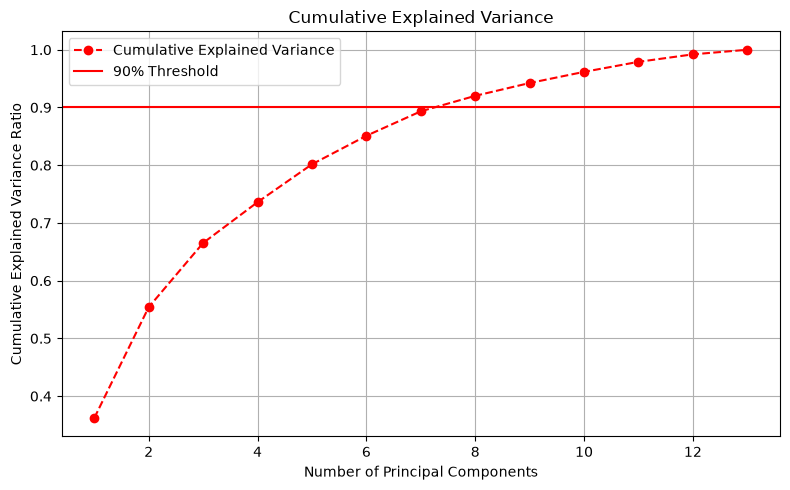

In [97]:
cumulative_variance=np.cumsum(explained_variance)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker='o', linestyle='--', color='r', label='Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title("Cumulative Explained Variance")
plt.grid(True)
plt.tight_layout()
plt.axhline(y=0.90, color='r', linestyle='-', label='90% Threshold')
plt.legend()
plt.show()

In [98]:
y_binary=(df['target']==0).astype(int)

X_train, X_test, y_train, y_test=train_test_split(
    X_scaled, y_binary, random_state=42, test_size=0.2, stratify=y_binary
)

In [99]:
settings = {"n_estimators":[50, 100], "max_depth": [3,5] }
grid=GridSearchCV(
    RandomForestClassifier(random_state=42), settings, cv=5, scoring='f1', n_jobs=-1
)
grid.fit(X_train, y_train)

best_model=grid.best_estimator_
print("Best Model Parameters:", grid.best_params_)
print("Best Model F1 Score (Cross-Validation):", round(grid.best_score_, 4))


Best Model Parameters: {'max_depth': 3, 'n_estimators': 50}
Best Model F1 Score (Cross-Validation): 1.0


In [100]:
cv_scores=cross_val_score(best_model, X_train, y_train, cv=5, scoring='f1')
print("Cross-Validation F1 Scores:", [round(s, 4) for s in cv_scores])
print("Mean Cross-Validation F1 Score:", round(cv_scores.mean(), 4))

Cross-Validation F1 Scores: [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]
Mean Cross-Validation F1 Score: 1.0


In [101]:
y_pred=best_model.predict(X_test)
y_prob=best_model.predict_proba(X_test)[:, 1]

In [102]:
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob), 4))


Confusion Matrix:
 [[23  1]
 [ 1 11]]
Precision: 0.9167
Recall: 0.9167
F1-Score: 0.9167
ROC-AUC Score: 0.9965
